# Session 2 复现：搭一条眨眼检测的视频管线

对应课程 *Building a Blink Detection Pipeline*（`01-image-analysis.html`）。

上一节我们发现**光靠眨眼时长分不开全/半眨眼**。这一节换一个角度：直接从视频里
拿信息。核心问题只有一个：

> **眼睛开合时眼区亮度会变化，这个变化能不能当作眨眼的代理信号？**

管线分五步，每一步都对应课程里的一节：

1. 打开视频，看元数据 → 视频对计算机到底是什么
2. 转灰度 → 丢掉颜色，只留亮度
3. 估计并扣除全局亮度漂移 → 别把"天阴了"当成"眨眼了"
4. 归一化亮度 → 让整段视频的曝光一致
5. 框选眼区 + 跟踪 → 只保留有信息的那一小块

本 notebook 会真正跑一遍 1841 帧的视频（首次约 1 分钟，之后走缓存）。

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd()
if (PROJECT / "src").exists():
    sys.path.insert(0, str(PROJECT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

config.setup_matplotlib()

import video
import pipeline

pd.set_option("display.width", 120)

## 1. 视频的元数据

对计算机来说视频就是"一串图片 + 播放速度"。先看清楚这串图片有多大、多快。

In [2]:
info = video.video_info()
for key, value in info.items():
    print(f"{key:18s}: {value}")

file              : E:\_Materials_in_NWPU_\2026_Spring\project\Aberystwyth University\日程\AI sessions\ai_session\data\raw_videos\M-006.mp4
frame_count       : 1841
fps               : 59.93488876831253
width             : 1080
height            : 1920
duration_seconds  : 30.71666666666667


值得注意的三件事：

* **1080 × 1920** —— 这是竖屏手机拍的，宽度 1080、高度 1920（OpenCV 报的是
  width, height，所以别被"1080p"误导）。
* **59.93 fps** —— 不是整 60 fps，所以"一帧 = 1/60 秒"只是近似；做时间换算时
  必须用真实 fps，否则 30 秒会累积出几十毫秒的偏差。
* **30.72 秒 1841 帧** —— 一次眨眼大约 0.2–0.5 秒，也就是 12–30 帧；
  眨眼事件在这个时间尺度上只占 20% 左右的帧（后面会验证）。

In [3]:
# 试一试：读出超过总帧数的帧会发生什么？
try:
    video.read_frame(config.RAW_VIDEO, info["frame_count"] + 100)
except ValueError as exc:
    print("预期的错误 →", exc)

预期的错误 → Could not read frame 1941 from E:\_Materials_in_NWPU_\2026_Spring\project\Aberystwyth University\日程\AI sessions\ai_session\data\raw_videos\M-006.mp4


## 2. 看一眼单帧

OpenCV 用 **BGR** 存图，matplotlib 期待 **RGB**，所以显示前必须转换 ——
这是新手最常踩的坑（颜色会变成"蓝脸红衣"那种效果）。

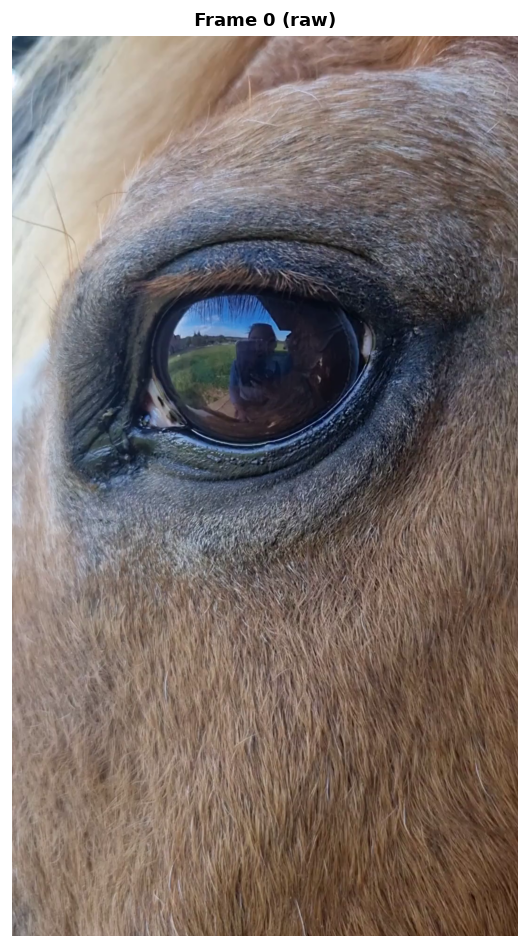

In [4]:
frame0 = video.read_frame(config.RAW_VIDEO, 0)
video.plot_frame(frame0, "Frame 0 (raw)", "fig20_frame0");

In [5]:
print("帧的形状:", frame0.shape, "→ (高, 宽, 通道)")
print("单个通道的取值范围:", frame0.min(), "-", frame0.max(), "（uint8）")
print("这一帧的像素总数:", frame0.shape[0] * frame0.shape[1])

帧的形状: (1920, 1080, 3) → (高, 宽, 通道)
单个通道的取值范围: 0 - 255 （uint8）
这一帧的像素总数: 2073600


一帧 1080×1920 的彩色图 = 207 万个像素 × 3 个通道 ≈ 6.2 MB 的原始数据。
1841 帧就是 **11 GB** 的未压缩数据 —— 这就是为什么不能"把所有帧都读进内存"，
必须流式处理（本项目第一遍遍历只保留每帧的均值，占用从 GB 降到 KB）。

## 3. 转灰度：为什么值得做

彩色图每像素 3 个数，灰度图每像素 1 个数：

* 数据量降到 1/3，后续计算更快；
* 眨眼关心的是"亮/暗"，不是"什么颜色"；
* 少一个维度，也少一处噪声来源。

代价是：如果**颜色**本身携带信息（例如血迹、皮肤泛红），灰度会把它丢掉。
对本任务而言这个代价可以接受。

In [6]:
import cv2

gray0 = cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY)
print("灰度后形状:", gray0.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
axes[0].imshow(cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB))
axes[0].set_title("Colour (BGR→RGB for display)")
axes[1].imshow(gray0, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Greyscale")
axes[2].hist(gray0.ravel(), bins=64, color="#555555")
axes[2].set_title("Brightness histogram")
axes[2].set_xlabel("Pixel value (0 = black, 255 = white)")
for ax in axes[:2]:
    ax.axis("off")
fig.tight_layout()
config.savefig(fig, "fig21_greyscale");
plt.close(fig)

灰度后形状: (1920, 1080)


## 4. 全局亮度：先把"环境变化"和"眨眼"分开

如果直接用亮度当眨眼信号，会立刻遇到一个问题：**整段视频的亮度本来就在漂**。
云飘过、马移动、相机自动曝光，都会让画面变亮或变暗，幅度可能比眨眼还大。

做法：算每帧的平均亮度 → 用**滚动中位数**（窗口 2 秒，比眨眼长）估计"此刻应该有多亮"
→ 二者相减，得到"相对于预期的偏差"。

In [7]:
stats = pipeline.build_frame_stats()
baseline, factors, reference = pipeline.build_global_baseline(stats, info["fps"])
print(f"全片平均亮度: {stats['global_mean'].mean():.2f}")
print(f"亮度基线参考值: {reference:.2f}")
print(f"归一化系数范围: {factors.min():.3f} – {factors.max():.3f}")

全片平均亮度: 112.16
亮度基线参考值: 112.38
归一化系数范围: 0.963 – 1.031


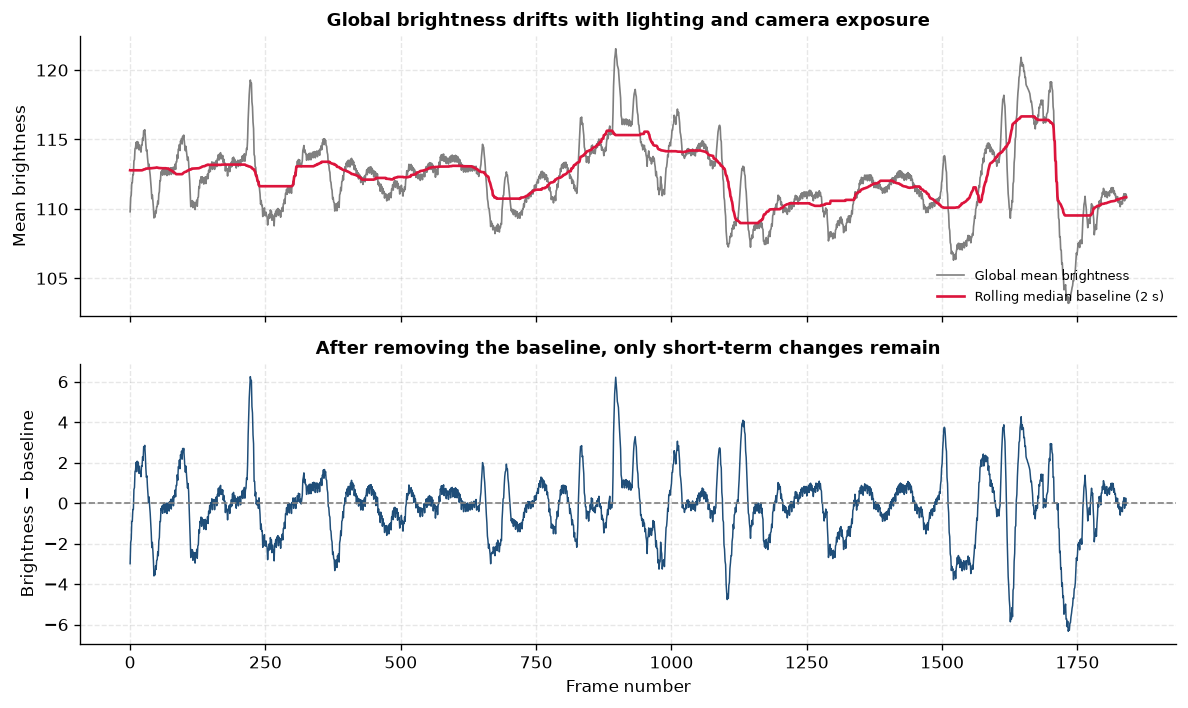

In [8]:
video.plot_global_brightness(stats, baseline);

上图第一行：全局亮度从 108 缓慢升到 118 又回落，跨度约 10 个灰度级（≈9%）。
第二行：扣掉基线之后，只剩下短时波动。这说明"缓慢漂移"和"短时事件"在时间尺度上
是可以分开的 —— 前提是窗口长度选对：

* 窗口太短 → 基线会跟着眨眼一起动，把信号扣没了；
* 窗口太长 → 跟不上真实的曝光变化，残留趋势进入信号。

课程用 2 秒。第 05 个 notebook 会把这件事**量化**（扫一遍窗口，用 AUC 选，而不是目测）。

## 5. 亮度归一化

有了基线，就可以把每帧乘一个修正系数，让整段视频"看起来一样亮"：

$$c_t = \text{clip}\left(\frac{\text{参考亮度}}{\text{基线}_t},\ 0.5,\ 2.0\right)$$

两个细节值得注意：

* **除以零保护**：基线为 0 时系数取 1；
* **裁剪到 [0.5, 2.0]**：防止某帧基线异常小导致系数爆炸，把整帧洗白。

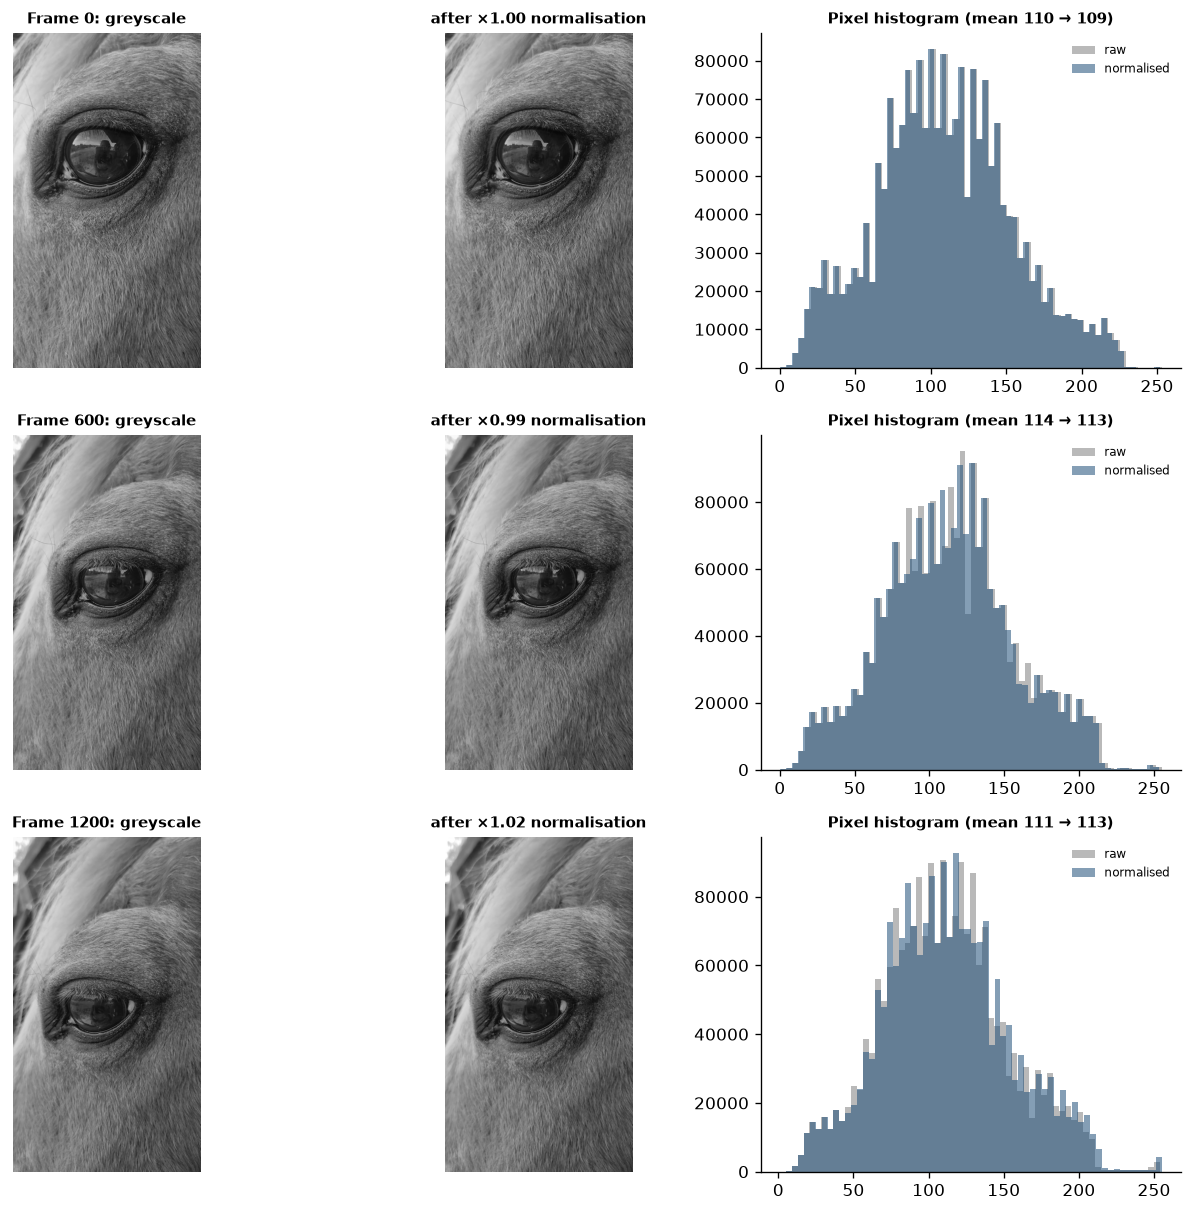

In [9]:
video.compare_normalisation(factors, frames=(0, 600, 1200));

最后一列是像素直方图：归一化把不同时刻的直方图**往同一个位置拉**。
这一步本身不产生眨眼信号，但它保证后面比较的"亮度"是同一个尺度上的。

## 6. 框选眼区（ROI）

全画面里 95% 的内容（马毛、背景、天空）和眨眼无关，而且会稀释亮度信号。
所以只在眼睛周围画一个框。

原课程用 `cv2.selectROI` 让人**手动**拖一个框。这带来一个隐蔽的问题：
**框是因人而异的，结果无法复现**。本项目把框固化成常量：

```python
EYE_BOX = (x, y, w, h) = (250, 470, 640, 560)
```

这样任何人重跑都能得到同样的数字。代价是换一段视频要重新定框。

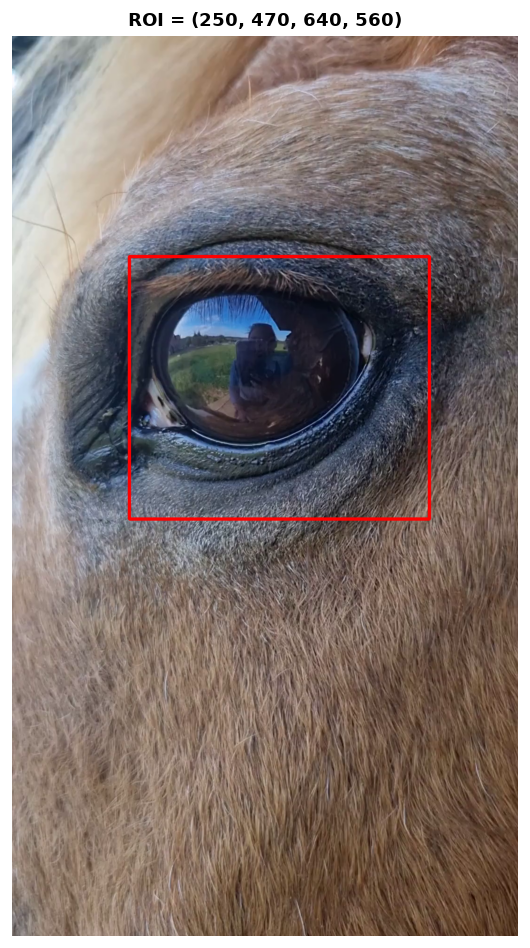

In [10]:
video.plot_frame_with_box(frame0, config.EYE_BOX,
                          f"ROI = {config.EYE_BOX}", "fig21b_roi_box");

In [11]:
x, y, w, h = config.EYE_BOX
crop0 = cv2.cvtColor(frame0, cv2.COLOR_BGR2GRAY)[y:y + h, x:x + w]
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.imshow(crop0, cmap="gray")
ax.set_title(f"Eye crop: {w}×{h} px, mean brightness {crop0.mean():.1f}")
ax.axis("off")
fig.tight_layout()
config.savefig(fig, "fig21c_eye_crop");
plt.close(fig)

框的大小是有讲究的（课程专门讨论过）：

* **太大** → 把背景和毛发也包含进来，跟踪器会去学背景纹理，亮度信号被稀释；
* **太小** → 眼睑被切掉，而眼睑正是"开合"发生的地方；
* **合适** → 包含眼球、上下眼睑、以及少量周围皮肤。

本项目的框覆盖整个眼球 + 上下眼睑，和原课程手选的框（900×662）在取景上基本一致。

## 7. 跟踪

马会动、相机会抖，框不能一直钉在同一个像素位置，所以要跟踪。

**跟踪器不懂"眼睛"**。它只知道：我给的这块图像长什么样（亮度分布、边缘、纹理），
下一帧里哪里最像。所以它跟的是"这块图案"，不是"眼睛"。

这也解释了跟踪失败的原因：眼睛闭上了、图案变了，跟踪器就可能跟丢；
一旦跟丢，它会开始在错误的位置更新自己 —— 这就是**漂移（drift）**。

课程为了加速，每 100 帧才真正调用一次 `tracker.update()`，中间帧直接复用上一个框。
下面这段代码用的就是这个设置。

In [12]:
roi_table = pipeline.build_roi_table()
print("跟踪器:", video.make_tracker()[1])
print("逐帧记录行数:", len(roi_table))
roi_table.head(3)

跟踪器: TrackerCSRT_create
逐帧记录行数: 1841


,frame,x,y,w,h,tracked,roi_mean,roi_median,roi_std,roi_p10,roi_p90,roi_grad_energy,roi_upper_mean,roi_lower_mean
0,0,249,470,640,560,True,62.933907,58.0,35.641495,22.0,113.0,60.379650,55.278023,70.589790
1,1,249,470,640,560,True,64.069679,59.0,35.712547,23.0,115.0,59.289570,56.139664,71.999718
2,2,249,470,640,560,True,64.392380,60.0,35.901615,23.0,115.0,59.916187,56.118610,72.666130


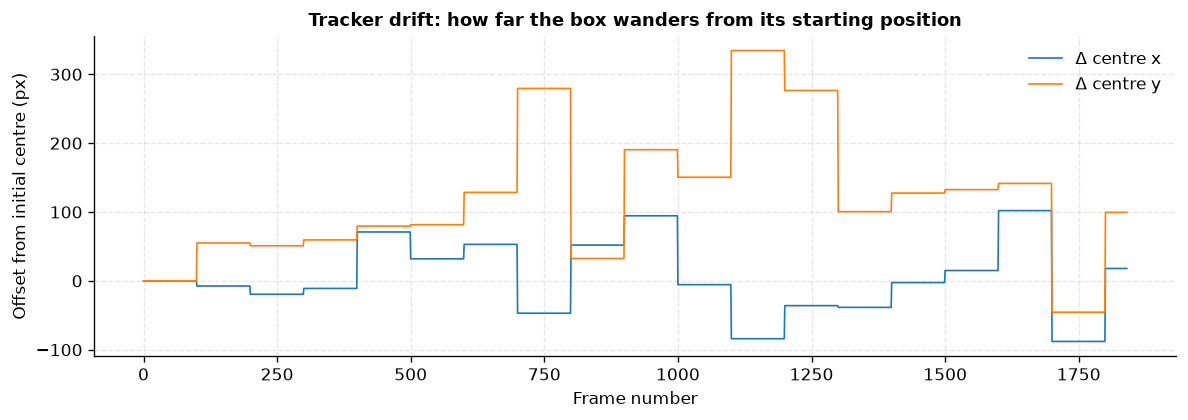

In [13]:
video.plot_tracking_drift(roi_table);

上图是框中心相对起始位置的位移。它缓慢增长到若干像素 —— 说明**框在慢慢漂**，
但因为每 100 帧才更新一次，漂移速度被限制了。这样做省时间，代价是框会滞后于真实的眼位。

第 05 个 notebook 会把这个取舍量化：把 `frame_step` 从 1 扫到 100，看漂移和
信号质量各变化多少。

## 8. 产物：眼区裁片

跟踪的最终产物是一段"只有眼睛"的视频（课程里的 `tracked_eye_box_.mp4`）。

In [14]:
tracked = config.TRACKED_VIDEO
print("文件:", tracked.name)
print("大小: %.1f MB" % (tracked.stat().st_size / 1e6))
cap = cv2.VideoCapture(str(tracked))
print("帧数:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
      "| 分辨率:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x",
      int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
      "| fps:", round(cap.get(cv2.CAP_PROP_FPS), 2))
cap.release()

文件: tracked_eye_crop.mp4
大小: 29.0 MB
帧数: 1841 | 分辨率: 640 x 560 | fps: 59.94


也可以把某一次眨眼的帧逐张存下来，用肉眼确认"亮度变化"这件事到底长什么样。
下面取第 600–660 帧（一次标注过的眨眼附近）每隔 8 帧存一张。

In [15]:
paths = video.save_crop_frames(range(600, 661, 8), config.CROPS_DIR, prefix="blink")
print(f"已保存 {len(paths)} 张裁片到 {config.CROPS_DIR.relative_to(PROJECT)}")

已保存 8 张裁片到 data\crops


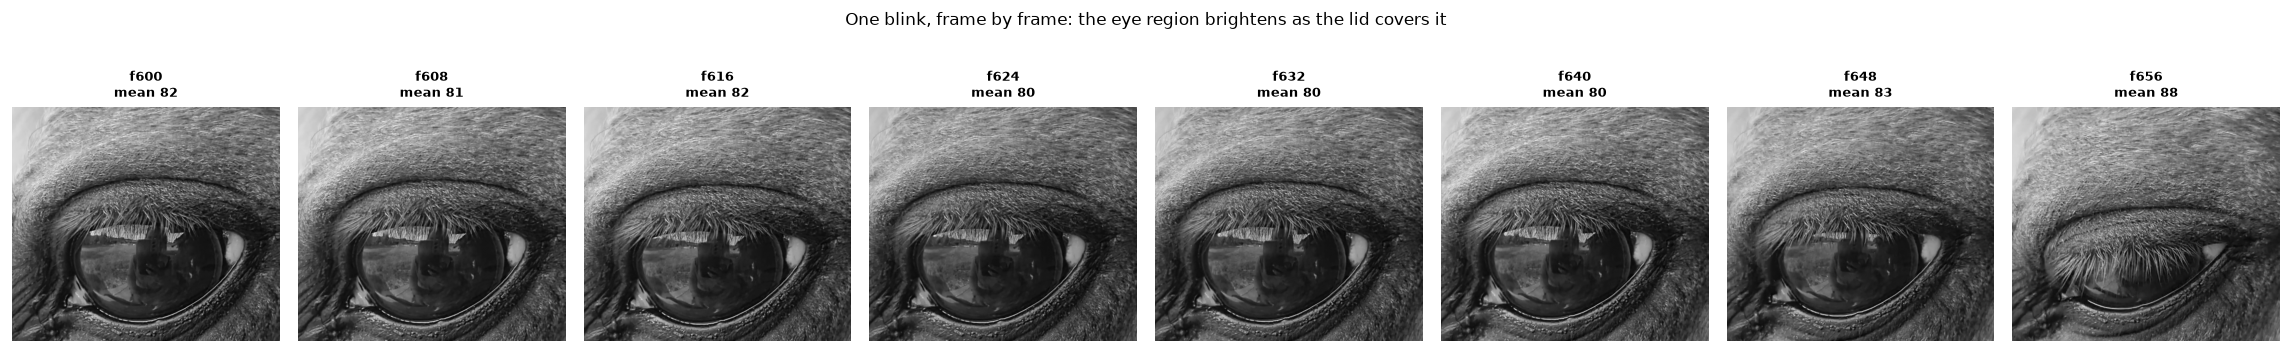

In [16]:
video.plot_blink_sequence(range(600, 661, 8));

序列图上标注了每帧的眼区平均亮度。可以看到：**眼睛睁开时（深色虹膜占主导）平均亮度较低，
眼睑合上时（浅色皮肤/毛发覆盖）平均亮度升高**。这正是"亮度可以当眨眼代理"的物理原因。
注意方向是**变亮**而不是变暗 —— 这一点因个体、光照而异，后面会用数据自动判定符号，
而不是写死。

## 9. 与课程对照

| 课程步骤 | 课程实现 | 本项目实现 | 是否一致 |
|---|---|---|---|
| 视频元数据 | 1841 帧 / 59.93 fps / 1080×1920 / 30.72 s | 完全相同 | ✅ |
| 灰度化 | 逐帧 `cvtColor`，存 130 MB 灰度视频 | 逐帧灰度，**不落盘**（只留统计量） | 数值一致，省磁盘 |
| 全局亮度去趋势 | 滚动中位数，2 s | 同 | ✅ |
| 参考亮度 | 112.38 | 112.38 | ✅ |
| 归一化系数裁剪 | [0.5, 2.0] | 同（本例实际范围 0.96–1.03） | ✅ |
| ROI 选择 | `cv2.selectROI` 手动框（900×662） | 固化为常量 (250,470,640,560) | 取景一致，**可复现** |
| 跟踪器 | CSRT，每 100 帧更新 | CSRT，每 100 帧更新 | ✅ |
| 眼区裁片视频 | `tracked_eye_box_.mp4` | `data/processed/tracked_eye_crop.mp4` | ✅ |

两处有意的差异：

1. **不落盘中间视频**。课程把灰度视频和归一化视频各存一份（合计约 265 MB）。
   本项目在第二遍读取时"边归一化边跟踪"，中间结果只保留逐帧标量 + 约 40 MB 的
   眼区裁片。数值完全一致，磁盘占用降了 6 倍。如果确实需要那两段视频，
   把 `pipeline.py` 里的 `track_video` 打开写盘即可。
2. **ROI 固化**。这是可复现性的必要代价：手动框选的结果无法在别人的机器上重现。

下一步：`03_session3_brightness_signal.ipynb` 从这段裁片里把亮度信号抠出来，
和人工标注的眨眼真值对上。

In [17]:
# 把本 notebook 的关键数字存一份，供报告引用
summary = {
    "frame_count": info["frame_count"],
    "fps": round(info["fps"], 3),
    "duration_s": round(info["duration_seconds"], 2),
    "reference_brightness": round(reference, 2),
    "correction_min": round(float(factors.min()), 3),
    "correction_max": round(float(factors.max()), 3),
    "eye_box": config.EYE_BOX,
    "tracked_video_mb": round(tracked.stat().st_size / 1e6, 1),
}
pd.Series(summary).to_csv(config.OUT_DIR / "session2_summary.csv")
summary

{'frame_count': 1841,
 'fps': 59.935,
 'duration_s': 30.72,
 'reference_brightness': 112.38,
 'correction_min': 0.963,
 'correction_max': 1.031,
 'eye_box': (250, 470, 640, 560),
 'tracked_video_mb': 29.0}